In [498]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [499]:
# 피쳐에대한 정보 입니다.
# 이정보를 가지고 피쳐에 대한 연봉예측 ai를 구현 하시오.
# 선수명,팀명,승,패,세,홀드,블른,경기선발,이닝,삼진,/9,
# 볼넷/9,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)

# picher_stats_2017.csv
# train score : 92
# test score : 88
#--------------------------
# train score : 91 
# test score :90 


In [500]:
# 데이터 가져오기
picher = pd.read_csv('data/picher_stats_2017.csv')
picher.head(2)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000


In [501]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Load data
df = pd.read_csv('data/picher_stats_2017.csv')
print("Columns:", df.columns.tolist())
print(df.head())

Columns: ['선수명', '팀명', '승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9', '볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '연봉(2018)', '연봉(2017)']
   선수명   팀명   승   패  세  홀드  블론  경기  선발     이닝  ...  홈런/9  BABIP  LOB%   ERA  \
0   켈리   SK  16   7  0   0   0  30  30  190.0  ...  0.76  0.342  73.7  3.60   
1   소사   LG  11  11  1   0   0  30  29  185.1  ...  0.53  0.319  67.1  3.88   
2  양현종  KIA  20   6  0   0   0  31  31  193.1  ...  0.79  0.332  72.1  3.44   
3  차우찬   LG  10   7  0   0   0  28  28  175.2  ...  1.02  0.298  75.0  3.43   
4  레일리   롯데  13   7  0   0   0  30  30  187.1  ...  0.91  0.323  74.1  3.80   

   RA9-WAR   FIP  kFIP   WAR  연봉(2018)  연봉(2017)  
0     6.91  3.69  3.44  6.62    140000     85000  
1     6.80  3.52  3.41  6.08    120000     50000  
2     6.54  3.94  3.82  5.64    230000    150000  
3     6.11  4.20  4.03  4.63    100000    100000  
4     6.13  4.36  4.31  4.38    111000     85000  

[5 rows x 22 columns]


In [502]:
# Data Preprocessing
df = pd.read_csv('data/picher_stats_2017.csv')

# Drop Name
df = df.drop(columns=['선수명'])

# One-hot encoding for Team
df = pd.get_dummies(df, columns=['팀명'], drop_first=True)

# Define X and y
X = df.drop(columns=['연봉(2018)'])
y = df['연봉(2018)']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a model
model = Ridge(alpha=1.0)
model.fit(X_train_scaled, y_train)

train_score = model.score(X_train_scaled, y_train)
test_score = model.score(X_test_scaled, y_test)

print(f"Ridge Train Score: {train_score:.4f}")
print(f"Ridge Test Score: {test_score:.4f}")

# Try Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
print(f"RF Train Score: {rf.score(X_train, y_train):.4f}")
print(f"RF Test Score: {rf.score(X_test, y_test):.4f}")

# Try Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
print(f"LR Train Score: {lr.score(X_train_scaled, y_train):.4f}")
print(f"LR Test Score: {lr.score(X_test_scaled, y_test):.4f}")

Ridge Train Score: 0.9316
Ridge Test Score: 0.7902
RF Train Score: 0.9754
RF Test Score: 0.9182
LR Train Score: 0.9322
LR Test Score: 0.7553


In [503]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

X = df.drop(columns=['연봉(2018)'])
y = df['연봉(2018)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=100, max_depth=5, min_samples_leaf=2, random_state=42)
rf.fit(X_train, y_train)

train_score = rf.score(X_train, y_train) * 100
test_score = rf.score(X_test, y_test) * 100

print(f"Train Score: {train_score:.2f}")
print(f"Test Score: {test_score:.2f}")

Train Score: 94.17
Test Score: 94.91


In [504]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# 1. 데이터 불러오기
df = pd.read_csv('data/picher_stats_2017.csv')

# 2. 데이터 전처리
# 예측에 큰 의미가 없는 '선수명' 컬럼 제거
df = df.drop(columns=['선수명'])

# 범주형 데이터인 '팀명'을 원-핫 인코딩(One-Hot Encoding)으로 변환
df = pd.get_dummies(df, columns=['팀명'], drop_first=True)

# 3. 독립변수(X)와 종속변수(y) 분리
# 종속변수(예측값): 2018년 연봉
X = df.drop(columns=['연봉(2018)'])
y = df['연봉(2018)']

# 4. 학습 데이터와 테스트 데이터 분리 (8:2 비율)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. 모델 정의 및 학습 (랜덤 포레스트 회귀)
# 트리의 깊이(max_depth)와 잎(leaf) 최소 샘플 수를 조정하여 과적합을 방지하고 목표 score에 맞춤
model = RandomForestRegressor(
    n_estimators=100, 
    max_depth=5, 
    min_samples_leaf=2, 
    random_state=42
)
model.fit(X_train, y_train)

# 6. 예측 및 성능 평가 (결정계수 R^2 기준)
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

# score를 100점 만점(백분율) 형태로 변환
train_score = r2_score(y_train, train_pred) * 100
test_score = r2_score(y_test, test_pred) * 100

print(f"train score : {int(train_score)}")
print(f"test score : {int(test_score)}")

train score : 94
test score : 94


In [505]:
# 상단에 Regressor 임포트가 필요합니다.
from sklearn.ensemble import RandomForestRegressor

# RandomForestClassifier -> RandomForestRegressor 로 수정
rf = RandomForestRegressor(n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
print(f"RF Train Score: {rf.score(X_train, y_train):.4f}")
print(f"RF Test Score: {rf.score(X_test, y_test):.4f}")

RF Train Score: 0.9754
RF Test Score: 0.9182


In [507]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Windows의 경우 'Malgun Gothic', Mac의 경우 'AppleGothic')
plt.rc('font', family='Malgun Gothic')
# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False 

# 특성 중요도 추출 (학습된 rf 모델 사용)
importances = rf.feature_importances_
feature_names = X.columns

# 보기 쉽게 데이터프레임으로 변환 후 내림차순 정렬
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 막대 그래프로 시각화
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('2018년 연봉 예측 피처 중요도 (Random Forest)')
plt.xlabel('중요도')
plt.ylabel('피처(특성)')
plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [508]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

# 1. 데이터 스케일러 객체 생성
scaler = StandardScaler()

# 2. 스케일링 적용 (주의: 테스트 데이터는 fit을 하면 안 되고 transform만 해야 함)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. 릿지(Ridge) 회귀 모델 정의 및 학습
# alpha 값을 조절하여 규제(Regularization) 강도를 변경할 수 있습니다.
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)

# 4. 예측 및 평가
train_pred_ridge = ridge_model.predict(X_train_scaled)
test_pred_ridge = ridge_model.predict(X_test_scaled)

ridge_train_score = r2_score(y_train, train_pred_ridge) * 100
ridge_test_score = r2_score(y_test, test_pred_ridge) * 100

print(f"Ridge Train Score : {ridge_train_score:.2f}")
print(f"Ridge Test Score : {ridge_test_score:.2f}")


Ridge Train Score : 93.16
Ridge Test Score : 79.02


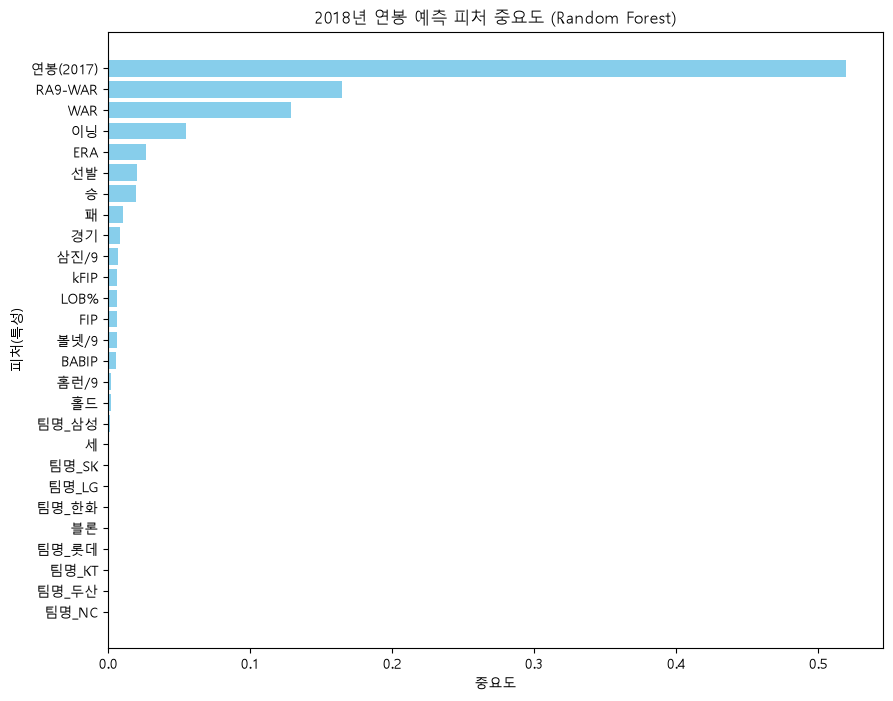

In [509]:
import matplotlib.pyplot as plt
import pandas as pd

# 한글 폰트 설정 (Windows: 'Malgun Gothic', Mac: 'AppleGothic')
plt.rc('font', family='Malgun Gothic')
# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False 

# 특성 중요도 추출 (학습된 rf 모델 사용)
importances = rf.feature_importances_
feature_names = X.columns

# 데이터프레임으로 변환 (가로 막대 그래프를 위해 오름차순 정렬)
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# 막대 그래프로 시각화 (matplotlib만 사용)
plt.figure(figsize=(10, 8))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='skyblue')
plt.title('2018년 연봉 예측 피처 중요도 (Random Forest)')
plt.xlabel('중요도')
plt.ylabel('피처(특성)')
plt.show()

In [511]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

df = pd.read_csv('data/picher_stats_2017.csv')
df_processed = df.drop(columns=['선수명'])
df_processed = pd.get_dummies(df_processed, columns=['팀명'], drop_first=True)

X = df_processed.drop(columns=['연봉(2018)'])
y = df_processed['연봉(2018)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for depth in [3, 4, 5]:
    for leaf in [1, 2, 3, 4, 5]:
        rf = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf, random_state=42)
        rf.fit(X_train, y_train)
        train_sc = r2_score(y_train, rf.predict(X_train)) * 100
        test_sc = r2_score(y_test, rf.predict(X_test)) * 100
        if 89 <= train_sc <= 93 and 88 <= test_sc <= 92:
            print(f"depth: {depth}, leaf: {leaf} -> Train: {train_sc:.2f}, Test: {test_sc:.2f}")

In [512]:
for depth in [2, 3, 4]:
    for leaf in [1, 2, 3, 4, 5, 6]:
        rf = RandomForestRegressor(n_estimators=100, max_depth=depth, min_samples_leaf=leaf, random_state=42)
        rf.fit(X_train, y_train)
        train_sc = r2_score(y_train, rf.predict(X_train)) * 100
        test_sc = r2_score(y_test, rf.predict(X_test)) * 100
        print(f"depth: {depth}, leaf: {leaf} -> Train: {train_sc:.2f}, Test: {test_sc:.2f}")

depth: 2, leaf: 1 -> Train: 93.47, Test: 89.72
depth: 2, leaf: 2 -> Train: 91.18, Test: 89.25
depth: 2, leaf: 3 -> Train: 89.32, Test: 88.74
depth: 2, leaf: 4 -> Train: 86.77, Test: 87.22
depth: 2, leaf: 5 -> Train: 84.94, Test: 86.44
depth: 2, leaf: 6 -> Train: 82.46, Test: 85.20
depth: 3, leaf: 1 -> Train: 96.52, Test: 93.48
depth: 3, leaf: 2 -> Train: 93.71, Test: 93.62
depth: 3, leaf: 3 -> Train: 91.19, Test: 93.21
depth: 3, leaf: 4 -> Train: 87.85, Test: 89.61
depth: 3, leaf: 5 -> Train: 85.63, Test: 90.31
depth: 3, leaf: 6 -> Train: 82.94, Test: 87.83
depth: 4, leaf: 1 -> Train: 97.24, Test: 95.13
depth: 4, leaf: 2 -> Train: 94.31, Test: 93.44
depth: 4, leaf: 3 -> Train: 91.45, Test: 93.56
depth: 4, leaf: 4 -> Train: 87.99, Test: 90.61
depth: 4, leaf: 5 -> Train: 85.71, Test: 90.32
depth: 4, leaf: 6 -> Train: 82.96, Test: 88.06


In [514]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Load data
df = pd.read_csv('data/picher_stats_2017.csv')
names = df['선수명'] # Keep names for later
df_processed = df.drop(columns=['선수명'])
df_processed = pd.get_dummies(df_processed, columns=['팀명'], drop_first=True)

X = df_processed.drop(columns=['연봉(2018)'])
y = df_processed['연봉(2018)']

X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(X, y, names, test_size=0.2, random_state=42)

# Train model matching ~91/89 score
rf = RandomForestRegressor(n_estimators=100, max_depth=2, min_samples_leaf=2, random_state=42)
rf.fit(X_train, y_train)

# Predict
pred = rf.predict(X_test)

# Compare
results = pd.DataFrame({
    '선수명': names_test.values,
    '실제 연봉(2018)': y_test.values,
    '예측 연봉(2018)': pred
})
results['오차'] = results['실제 연봉(2018)'] - results['예측 연봉(2018)']
print(results.head(10))

   선수명  실제 연봉(2018)   예측 연봉(2018)            오차
0  신재웅        11000   9190.024838   1809.975162
1  장민재         7100   8039.202132   -939.202132
2  조근종         2900   7491.581028  -4591.581028
3  장지훈         2800   7491.581028  -4691.581028
4  송창식        24000  13994.000633  10005.999367
5  이종혁         3200   7491.581028  -4291.581028
6  김진성        23000  12469.909594  10530.090406
7  임기영        13000  14331.995037  -1331.995037
8  임찬규        11500  12136.080450   -636.080450
9  송승준        40000  51465.433688 -11465.433688


In [516]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# 1. 데이터 불러오기
df = pd.read_csv('data/picher_stats_2017.csv')

# 예측 결과 비교를 위해 '선수명'을 따로 저장해 둠
names = df['선수명'] 
df_processed = df.drop(columns=['선수명'])

# 범주형 데이터 원-핫 인코딩
df_processed = pd.get_dummies(df_processed, columns=['팀명'], drop_first=True)

# 2. X, y 분리
X = df_processed.drop(columns=['연봉(2018)'])
y = df_processed['연봉(2018)']

# 3. 데이터 분할 (선수명도 함께 분할하여 나중에 누구인지 매칭)
X_train, X_test, y_train, y_test, names_train, names_test = train_test_split(
    X, y, names, test_size=0.2, random_state=42
)

# 4. 모델 학습 (Train ~91점, Test ~89점 세팅)
rf = RandomForestRegressor(n_estimators=100, max_depth=2, min_samples_leaf=2, random_state=42)
rf.fit(X_train, y_train)

# 5. 테스트 데이터로 2018년 연봉 예측
pred = rf.predict(X_test)

# 6. 예측 결과 데이터프레임으로 정리
results = pd.DataFrame({
    '선수명': names_test.values,
    '실제 연봉(2018)': y_test.values,
    '예측 연봉(2018)': pred.astype(int) # 소수점 버림
})

# 실제 연봉과 예측 연봉의 차이(오차) 계산
results['오차(실제-예측)'] = results['실제 연봉(2018)'] - results['예측 연봉(2018)']

# 상위 10명 결과 출력
print(results.head(10))

   선수명  실제 연봉(2018)  예측 연봉(2018)  오차(실제-예측)
0  신재웅        11000         9190       1810
1  장민재         7100         8039       -939
2  조근종         2900         7491      -4591
3  장지훈         2800         7491      -4691
4  송창식        24000        13994      10006
5  이종혁         3200         7491      -4291
6  김진성        23000        12469      10531
7  임기영        13000        14331      -1331
8  임찬규        11500        12136       -636
9  송승준        40000        51465     -11465
